# UFAL · Typhoon HIL — Prática 1: caracterização em malha aberta

**Conversor Buck · Comparação entre teoria e Virtual HIL**  
Ensaios: (A) degrau de razão cíclica, $D:0{,}25\to0{,}375$, com $R=10\,\Omega$; (B) degrau de carga $R:10\to5\,\Omega$, com $D=0{,}375$.

Este notebook usa os **dois CSVs exportados após a adição do sensor `Ia3`**. Os valores exibidos são derivados diretamente dos arquivos; não são estimativas de capturas de tela. A análise média ignora chaveamento e perdas, enquanto as métricas dos dados usam uma suavização de um período PWM.

**Como executar:** coloque `buck.ipynb` em `Analysis/` e os arquivos em `Analysis/data/`; execute **Run All**. Bibliotecas: `numpy`, `pandas`, `scipy`, `matplotlib`, `IPython`. A pasta `Results/` é criada automaticamente ao lado de `Analysis/`.

**Nota sobre o tempo:** as exportações têm o tempo zero associado ao trigger analógico da tensão, e não ao comando. O instante de comutação real é inferido dos dados com aproximação, sendo explicitado nas comparações.

In [2]:
%pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from IPython.display import display

BASE = Path.cwd()
DATA = BASE / 'data'
if not (DATA / 'duty_step.csv').exists() and (BASE / 'Analysis' / 'data' / 'duty_step.csv').exists():
    BASE = BASE / 'Analysis'
    DATA = BASE / 'data'
RESULTS = BASE.parent / 'Results' if BASE.name == 'Analysis' else BASE / 'Results'
RESULTS.mkdir(parents=True, exist_ok=True)

VIN, L, C, FS = 48.0, 97.5e-6, 100e-6, 40000.0
TPWM = 1 / FS
D0, D1, D_LOAD = 0.25, 0.375, 0.375
R0, R1 = 10.0, 5.0

csvs = {'Duty': DATA / 'duty_step.csv', 'Carga': DATA / 'load_step.csv'}
data = {}
for kind, f in csvs.items():
    df = pd.read_csv(f)
    expected = {'Time', 'Va1', 'Vs1', 'Ia1', 'Ia2', 'Ia3'}
    assert expected.issubset(df.columns), f'Colunas ausentes em {f}'
    assert df.Time.is_monotonic_increasing, f'Tempo não crescente em {f}'
    dt = np.median(np.diff(df.Time))
    df['Vout_avg'] = df.Va1.rolling(max(3, int(round(TPWM/dt))), center=True, min_periods=1).mean()
    df['Iload_avg'] = df.Ia1.rolling(max(3, int(round(TPWM/dt))), center=True, min_periods=1).mean()
    df['IL_avg'] = df.Ia3.rolling(max(3, int(round(TPWM/dt))), center=True, min_periods=1).mean()
    df['IC_avg'] = df.Ia2.rolling(max(3, int(round(TPWM/dt))), center=True, min_periods=1).mean()
    data[kind] = df
    print(f'{kind}: {len(df):,} amostras, dt={dt*1e6:.3f} µs, janela {df.Time.min()*1e3:.3f} a {df.Time.max()*1e3:.3f} ms')

Duty: 20,000 amostras, dt=0.500 µs, janela -3.000 a 6.999 ms
Carga: 20,000 amostras, dt=0.500 µs, janela -3.000 a 6.999 ms


## 1. Equações e previsões analíticas

Para componentes ideais, em modo de condução contínua (CCM), o modelo médio é:

$$\frac{di_L}{dt}=\frac{D V_{in}-v_o}{L},\qquad \frac{dv_o}{dt}=\frac{i_L-v_o/R}{C}.$$

Para pequenas variações de razão cíclica com carga constante:

$$G_{vd}(s)=\frac{\widetilde V_o(s)}{\widetilde D(s)}=\frac{V_{in}}{LCs^2+(L/R)s+1}.$$

Em regime: $V_o\approx DV_{in}$, $I_L\approx I_{load}=V_o/R$. Para indutor em CCM, desconsiderando perdas e ESR:

$$\Delta i_{L,pp}\approx\frac{V_{in}D(1-D)}{Lf_s},\qquad \Delta v_{o,pp}\approx\frac{\Delta i_{L,pp}}{8 f_s C}.$$

**Valores esperados:** em A, $V_o:12\to18\,\mathrm{V}$ e $I_{load}:1{,}2\to1{,}8\,\mathrm{A}$; em B, $V_o\approx18\,\mathrm{V}$ e $I_{load}:1{,}8\to3{,}6\,\mathrm{A}$.

In [4]:
def steady(d, r):
    v = VIN*d
    di = VIN*d*(1-d)/(L*FS)
    return {'Vout_V': v, 'Iload_A': v/r, 'IL_A': v/r,
            'IL_ripple_App': di, 'Vout_ripple_Vpp': di/(8*FS*C)}

analytic = pd.DataFrame([
    {'Experimento': 'Duty', 'Estado': 'Antes', 'D': D0, 'R_ohm': R0, **steady(D0,R0)},
    {'Experimento': 'Duty', 'Estado': 'Depois', 'D': D1, 'R_ohm': R0, **steady(D1,R0)},
    {'Experimento': 'Carga', 'Estado': 'Antes', 'D': D_LOAD, 'R_ohm': R0, **steady(D_LOAD,R0)},
    {'Experimento': 'Carga', 'Estado': 'Depois', 'D': D_LOAD, 'R_ohm': R1, **steady(D_LOAD,R1)},
])
display(analytic.round(5))
analytic.to_csv(RESULTS/'previsoes_analiticas.csv',index=False)

rows=[]
for r in (R0,R1):
    wn=1/np.sqrt(L*C)
    zeta=np.sqrt(L/C)/(2*r)
    roots=np.roots([L*C,L/r,1])
    rows.append({'R_ohm':r,'omega_n_rad_s':wn,'f_n_Hz':wn/(2*np.pi),
                 'zeta':zeta,'polos':str(roots)})
display(pd.DataFrame(rows))

,Experimento,Estado,D,R_ohm,Vout_V,Iload_A,IL_A,IL_ripple_App,Vout_ripple_Vpp
0,Duty,Antes,0.250,10.0,12.0,1.2,1.2,2.30769,0.07212
1,Duty,Depois,0.375,10.0,18.0,1.8,1.8,2.88462,0.09014
2,Carga,Antes,0.375,10.0,18.0,1.8,1.8,2.88462,0.09014
3,Carga,Depois,0.375,5.0,18.0,3.6,3.6,2.88462,0.09014


,R_ohm,omega_n_rad_s,f_n_Hz,zeta,polos
0,10.0,10127.393671,1611.824763,0.049371,[-500.+10115.04337925j -500.-10115.04337925j]
1,5.0,10127.393671,1611.824763,0.098742,[-1000.+10077.9016945j -1000.-10077.9016945j]


## 2. Referência temporal e condições iniciais

**Janelas de média em regime:** antes do evento: −2,5 a −1,0 ms; depois: 5,0 a 6,5 ms, evitando bordas e oscilação transitória. O CSV do degrau de carga permite detectar o comando pela alteração de $I_{load}/V_o=1/R$. Para o degrau de duty, o evento é estimado pela primeira alteração sustentada da tensão média acima da ondulação; pode haver atraso elétrico entre mudança de duty e resposta de tensão. **Não se afirma precisão de microssegundos para o instante do comando.**

In [5]:
PRE=(-.0025,-.0010); POST=(.005,.0065)
def win(df, a, b):
    return df[(df.Time >= a) & (df.Time < b)]
def detect_event(kind, df):
    t = df.Time.to_numpy()
    if kind == 'Carga':
        # Condutância efetiva: 1/R = Ia1/Va1. Detecta a comutação do ramo R2.
        g = (df.Ia1 / df.Va1).to_numpy()
        ix = np.flatnonzero((t > -.0007) & (g > (1/R0 + 1/R1)/2))[0]
        return float(t[ix]), 'condutância medida Ia1/Va1'
    # Primeiro desvio sustentado > 0.20 V do patamar inicial (não equivale exatamente ao comando)
    base=float(win(df,*PRE).Vout_avg.mean())
    y=df.Vout_avg.to_numpy()
    mask=(t > -.0007) & (y > base + .20)
    counts=np.convolve(mask.astype(int),np.ones(15,dtype=int),mode='same')
    ix=np.flatnonzero(mask & (counts>=12))[0]
    return float(t[ix]), 'início da resposta de tensão (aproximação)'

onsets={}
for kind,df in data.items():
    onset, how=detect_event(kind,df)
    onsets[kind]=onset
    print(f'{kind}: t_evento ≈ {onset*1e3:.4f} ms; critério: {how}; trigger em t=0 ms')

Duty: t_evento ≈ -0.0790 ms; critério: início da resposta de tensão (aproximação); trigger em t=0 ms
Carga: t_evento ≈ -0.0255 ms; critério: condutância medida Ia1/Va1; trigger em t=0 ms


## 3. Conservação de corrente — lei de Kirchhoff

De acordo com o sentido dos sensores do esquemático:

$$i_{L}(t)=i_C(t)+i_{load}(t), \quad \epsilon_{KCL}(t)=Ia3-Ia2-Ia1.$$

Verificamos **amostra por amostra**, sem suavização. O erro residual deve ser comparável à precisão de arredondamento do CSV. Esse teste é uma checagem interna consistente das medições, não uma prova independente de fidelidade física do modelo.

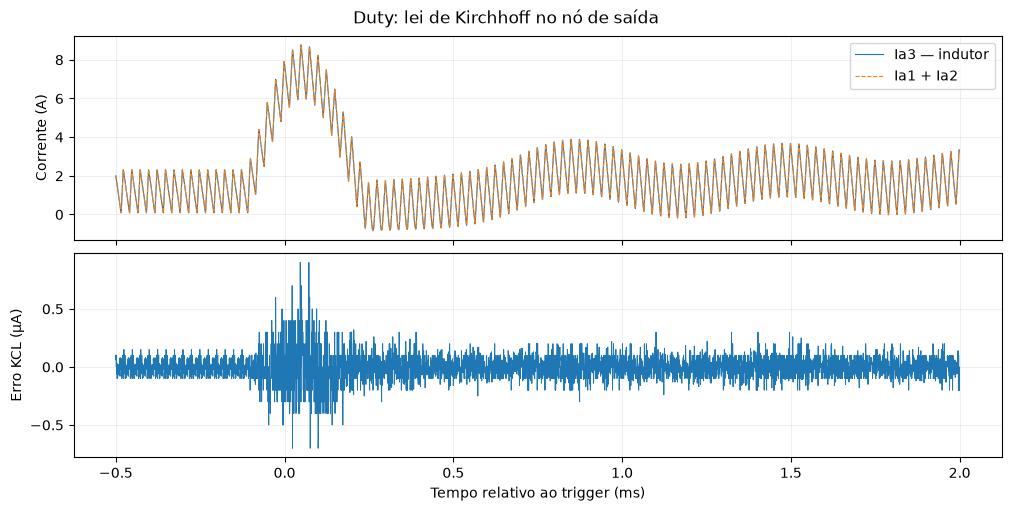

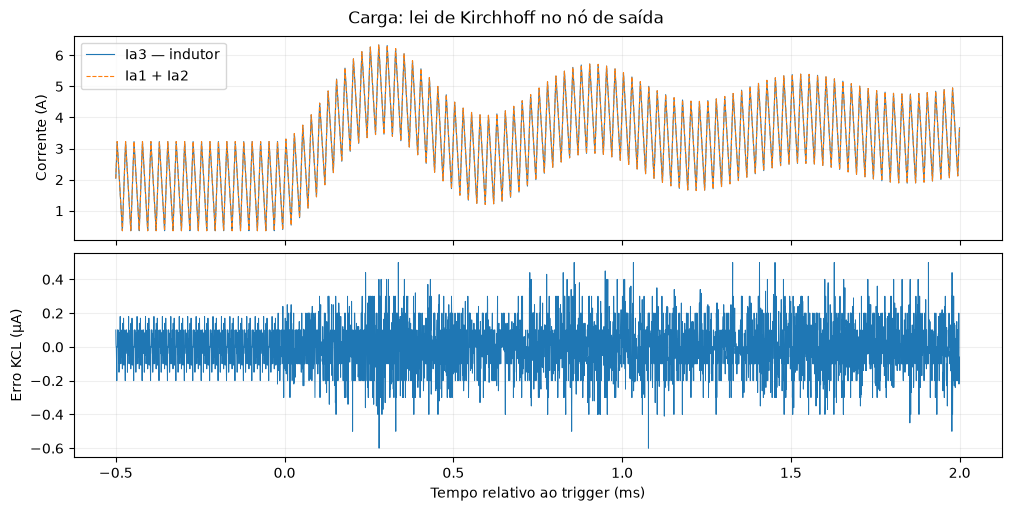

,Experimento,erro_max_A,erro_RMS_A,erro_max_uA
0,Duty,9.000000e-07,8.442327e-08,0.9
1,Carga,7.000000e-07,1.318831e-07,0.7


In [6]:
kcl_rows=[]
for kind,df in data.items():
    err=(df.Ia3-df.Ia2-df.Ia1).to_numpy()
    kcl_rows.append({'Experimento':kind,'erro_max_A':np.max(np.abs(err)),
                     'erro_RMS_A':np.sqrt(np.mean(err**2)),
                     'erro_max_uA':np.max(np.abs(err))*1e6})
    fig,ax=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
    s=win(df,-.0005,.002)
    ax[0].plot(s.Time*1e3,s.Ia3,lw=.8,label='Ia3 — indutor')
    ax[0].plot(s.Time*1e3,s.Ia1+s.Ia2,lw=.8,ls='--',label='Ia1 + Ia2')
    ax[0].set_ylabel('Corrente (A)');ax[0].legend();ax[0].grid(alpha=.2)
    ax[1].plot(s.Time*1e3,(s.Ia3-s.Ia2-s.Ia1)*1e6,lw=.7)
    ax[1].set_ylabel('Erro KCL (µA)');ax[1].set_xlabel('Tempo relativo ao trigger (ms)');ax[1].grid(alpha=.2)
    fig.suptitle(f'{kind}: lei de Kirchhoff no nó de saída')
    fig.savefig(RESULTS/f'kcl_{kind.lower()}.png',dpi=150);plt.show()
kcl=pd.DataFrame(kcl_rows);display(kcl);kcl.to_csv(RESULTS/'validacao_kcl.csv',index=False)

## 4. Comparação de regime permanente — teoria × simulação

Os valores simulados são a média de janelas estacionárias. São apresentados erros relativos para tensão, corrente de carga e corrente do indutor. O capacitor deve ter corrente média aproximadamente nula no regime.

In [7]:
steady_rows=[]
for kind,df in data.items():
    for stage,interval in [('Antes',PRE),('Depois',POST)]:
        s=win(df,*interval)
        a=analytic[(analytic.Experimento==kind)&(analytic.Estado==stage)].iloc[0]
        for signal,teo in [('Va1','Vout_V'),('Ia1','Iload_A'),('Ia3','IL_A')]:
            sim=s[signal].mean(); expected=a[teo]
            steady_rows.append({'Experimento':kind,'Estado':stage,'Sinal':signal,
                         'Teorico':expected,'Simulado':sim,
                         'Erro_%':100*abs(sim-expected)/abs(expected)})
steady_table=pd.DataFrame(steady_rows)
display(steady_table.round(6))
steady_table.to_csv(RESULTS/'comparacao_regime.csv',index=False)
print('Corrente média de capacitor:')
for kind,df in data.items():
    print(kind,'antes',win(df,*PRE).Ia2.mean(),'A; depois',win(df,*POST).Ia2.mean(),'A')

,Experimento,Estado,Sinal,Teorico,Simulado,Erro_%
0,Duty,Antes,Va1,12.0,11.996688,0.027598
1,Duty,Antes,Ia1,1.2,1.199669,0.027598
2,Duty,Antes,Ia3,1.2,1.199629,0.030892
3,Duty,Depois,Va1,18.0,17.989677,0.057349
4,Duty,Depois,Ia1,1.8,1.798968,0.057349
5,Duty,Depois,Ia3,1.8,1.804633,0.257402
6,Carga,Antes,Va1,18.0,17.995010,0.027721
7,Carga,Antes,Ia1,1.8,1.799501,0.027722
8,Carga,Antes,Ia3,1.8,1.799262,0.041013
9,Carga,Depois,Va1,18.0,17.989134,0.060367


Corrente média de capacitor:
Duty antes -3.9532723999994377e-05 A; depois 0.005665526430019994 A
Carga antes -0.0002392487200000127 A; depois 8.13828599999648e-06 A


## 5. Modelo médio no domínio do tempo

A integração numérica usa as **condições iniciais teóricas** em regime e uma comutação ideal de $D$ ou $R$ no instante estimado. O resultado é sobreposto às medições filtradas por um período PWM. As discrepâncias podem vir de discretização, componentes não ideais, modulação, detecção do evento e ausência de ESR no modelo.

Para o degrau de carga, considere que o estado $[i_L,v_o]$ **permanece contínuo** no instante de fechamento da chave, embora $i_{load}=v_o/R$ salte.

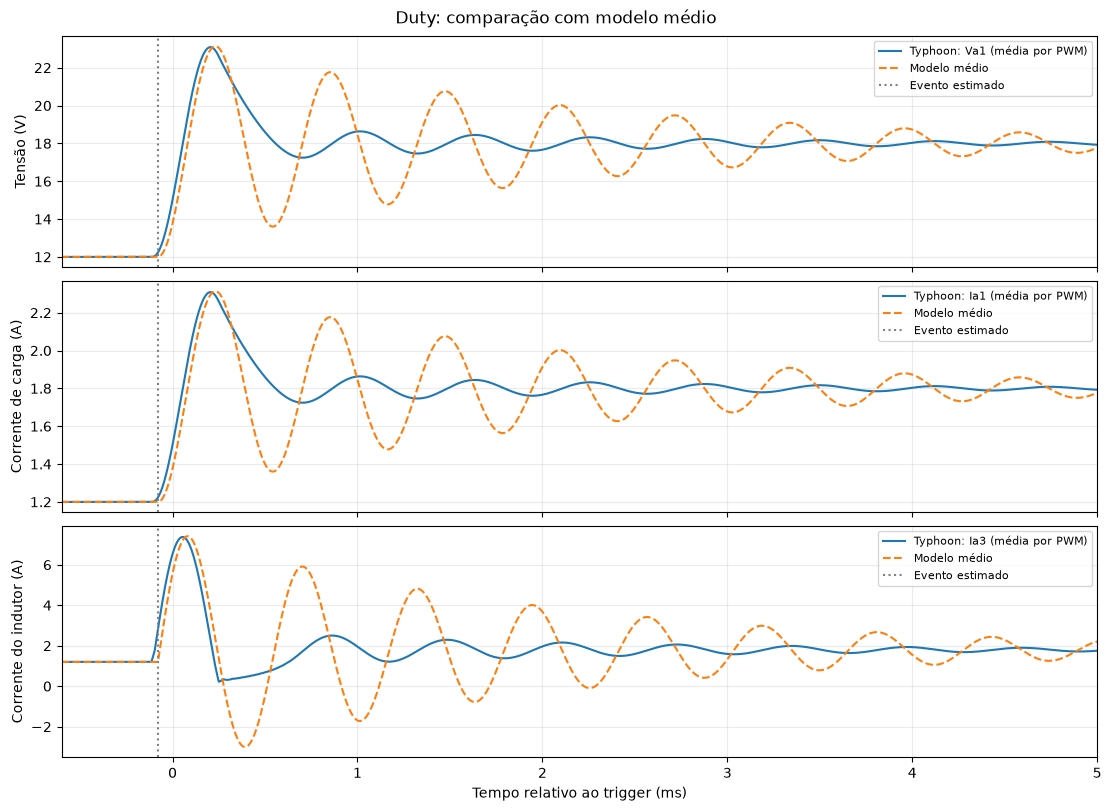

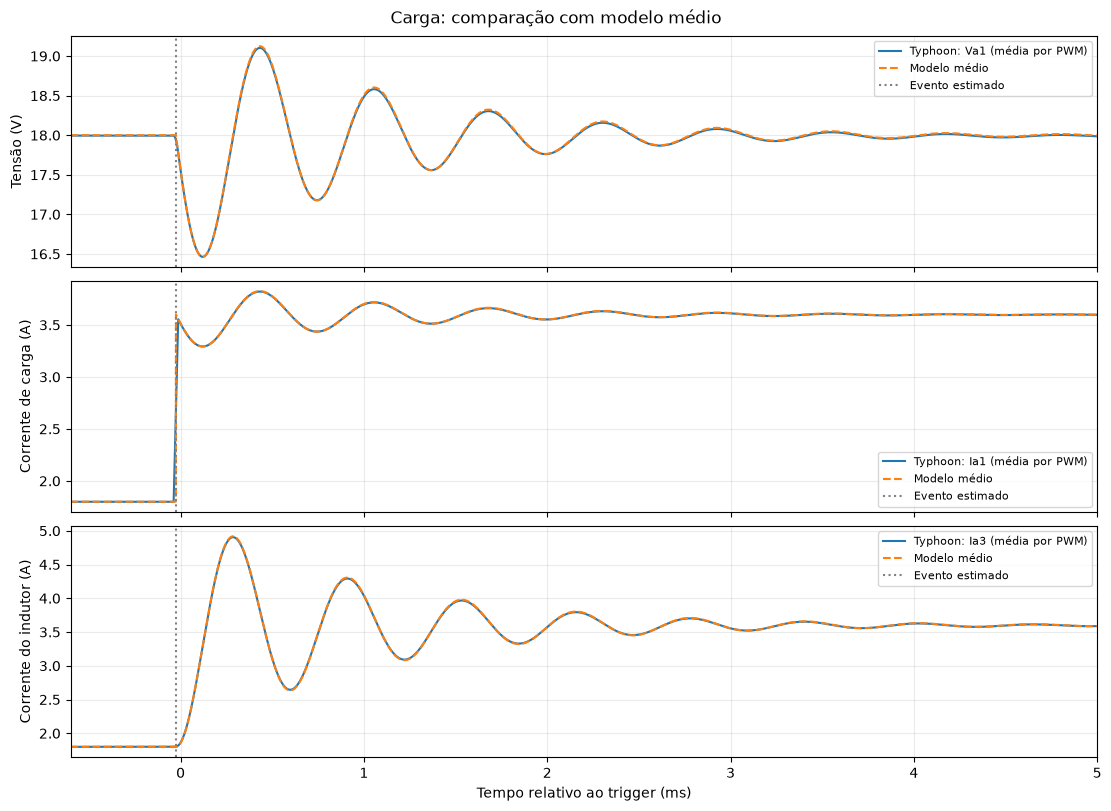

In [8]:
def solve_mean(kind, df):
    t=df.Time.to_numpy(); t0=onsets[kind]
    if kind=='Duty':
        duty_a,duty_b=D0,D1; r_a=r_b=R0
    else:
        duty_a=duty_b=D_LOAD; r_a,r_b=R0,R1
    x0=[VIN*duty_a/r_a,VIN*duty_a]
    def rhs(d,r):
        return lambda tt,x: [(VIN*d-x[1])/L,(x[0]-x[1]/r)/C]
    sol=np.empty((len(t),2))
    before=t<t0
    sol[before]=x0
    after=~before
    ts=t[after]
    ivp=solve_ivp(rhs(duty_b,r_b),(t0,ts[-1]),x0,t_eval=ts,rtol=1e-9,atol=1e-11,max_step=2e-6)
    if not ivp.success: raise RuntimeError(ivp.message)
    sol[after]=ivp.y.T
    return pd.DataFrame({'Time':t,'Model_IL':sol[:,0],'Model_Va1':sol[:,1],
                         'Model_Iload':sol[:,1]/np.where(t<t0,r_a,r_b)})

models={kind:solve_mean(kind,df) for kind,df in data.items()}
for kind,df in data.items():
    model=models[kind]
    fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True,layout='constrained')
    axes[0].plot(df.Time*1e3,df.Vout_avg,label='Typhoon: Va1 (média por PWM)')
    axes[0].plot(model.Time*1e3,model.Model_Va1,'--',label='Modelo médio')
    axes[1].plot(df.Time*1e3,df.Iload_avg,label='Typhoon: Ia1 (média por PWM)')
    axes[1].plot(model.Time*1e3,model.Model_Iload,'--',label='Modelo médio')
    axes[2].plot(df.Time*1e3,df.IL_avg,label='Typhoon: Ia3 (média por PWM)')
    axes[2].plot(model.Time*1e3,model.Model_IL,'--',label='Modelo médio')
    for ax,ylabel in zip(axes,['Tensão (V)','Corrente de carga (A)','Corrente do indutor (A)']):
        ax.axvline(onsets[kind]*1e3,ls=':',color='gray',label='Evento estimado')
        ax.set_ylabel(ylabel);ax.grid(alpha=.25);ax.legend(loc='best',fontsize=8)
    axes[2].set_xlabel('Tempo relativo ao trigger (ms)')
    axes[2].set_xlim(-.6,5)
    fig.suptitle(f'{kind}: comparação com modelo médio')
    fig.savefig(RESULTS/f'buck_{kind.lower()}_comparacao.png',dpi=160)
    plt.show()

## 6. Métricas transitórias

A tensão é suavizada em uma janela de **25 µs** para separar ondulação PWM da resposta dinâmica. As métricas são calculadas a partir do instante de evento **estimado** e das médias estacionárias:

- **Duty:** sobressinal em relação à amplitude do degrau $\Delta V=V_f-V_i$; tempo de subida de 10% a 90% dessa variação; acomodação dentro de **±2% da amplitude do degrau**, considerada até o fim da captura.
- **Carga:** afundamento e pico em relação a $V_f$; acomodação dentro de **±2% de $V_f$**. O tempo de subida não é aplicável porque a tensão retorna à mesma referência.

Essas **duas definições de banda** são diferentes e ficam explícitas para não comparar os tempos sem o contexto correto. O tempo de acomodação é o último instante em que a resposta sai da banda, relativo ao evento detectado.

In [9]:
def linear_crossing(t,y,threshold,start=0):
    ids=np.flatnonzero((np.arange(len(t))>start)&(y>=threshold))
    if not len(ids): return np.nan
    i=int(ids[0]); p=max(i-1,0)
    if y[i]==y[p]:return t[i]
    return t[p]+(threshold-y[p])*(t[i]-t[p])/(y[i]-y[p])

def transient_metrics(kind,df):
    t=df.Time.to_numpy();y=df.Vout_avg.to_numpy()
    initial=win(df,*PRE).Vout_avg.mean();final=win(df,*POST).Vout_avg.mean()
    event=onsets[kind];s=(t>=event)&(t<=.005)
    te=t[s];ye=y[s];t_rel=te-event
    if kind=='Duty':
        delta=final-initial; rise10=linear_crossing(te,ye,initial+.1*delta)
        rise90=linear_crossing(te,ye,initial+.9*delta)
        rise=(rise90-rise10)*1e3 if np.isfinite(rise10+rise90) else np.nan
        band=.02*abs(delta)
        over=100*(ye.max()-final)/abs(delta)
        dip=np.nan
    else:
        rise=np.nan;over=100*(ye.max()-final)/abs(final)
        dip=100*(final-ye.min())/abs(final)
        band=.02*abs(final)
    full_after=np.flatnonzero(t>=event)
    outside=full_after[np.abs(y[full_after]-final)>band]
    settling=(t[outside[-1]]-event)*1e3 if len(outside) else 0.
    return {'Experimento':kind,'Evento_estimado_ms':event*1e3,
       'Tensao_inicial_V':initial,'Tensao_final_V':final,
       'Tensao_minima_V':ye.min(),'Tensao_maxima_V':ye.max(),
       'Sobressinal_%':over,'Afundamento_%':dip,'Tempo_subida_10_90_ms':rise,
       'Tempo_acomodacao_ms':settling,'Banda_acomodacao_V':band}
metricas=pd.DataFrame([transient_metrics(k,d) for k,d in data.items()]);display(metricas.T.round(5))
metricas.to_csv(RESULTS/'metricas_transitorias.csv',index=False)

,0,1
Experimento,Duty,Carga
Evento_estimado_ms,-0.079,-0.0255
Tensao_inicial_V,11.996688,17.99501
Tensao_final_V,17.989676,17.989135
Tensao_minima_V,12.234759,16.462753
Tensao_maxima_V,23.08831,19.1032
Sobressinal_%,85.076656,6.192983
Afundamento_%,NaN,8.485024
Tempo_subida_10_90_ms,0.105447,NaN
Tempo_acomodacao_ms,4.241,1.4515


## 7. Ondulação do indutor e capacitor em regime

Calculamos $\Delta I_{L,pp}$, $\Delta V_{out,pp}$ e $\Delta I_{C,pp}$ como a **mediana de amplitudes pico a pico de 5 períodos PWM individuais**, em janelas afastadas dos transientes. Isso reduz a influência de deriva lenta do nível médio sobre a medida de ripple. O ripple de tensão teórico despreza ESR; o ripple do indutor supõe CCM.

Relações esperadas: $i_C=i_L-i_{load}$ e $\Delta I_{C,pp}\approx\Delta I_{L,pp}$, já que a corrente resistiva tem ripple pequeno.

,Experimento,Estado,D,R_ohm,Ripple_Ia3_App,Ripple_Ia3_teorico_App,Erro_ripple_Ia3_%,Ripple_Ia2_App,Ripple_Va1_mVpp,Ripple_Va1_teorico_mVpp
0,Duty,Antes,0.250,10.0,2.2178,2.3077,3.8936,2.2178,72.206,72.1154
1,Duty,Depois,0.375,10.0,2.7697,2.8846,3.9829,2.7692,82.850,90.1442
2,Carga,Antes,0.375,10.0,2.8657,2.8846,0.6571,2.8655,90.196,90.1442
3,Carga,Depois,0.375,5.0,2.8660,2.8846,0.6455,2.8658,90.117,90.1442


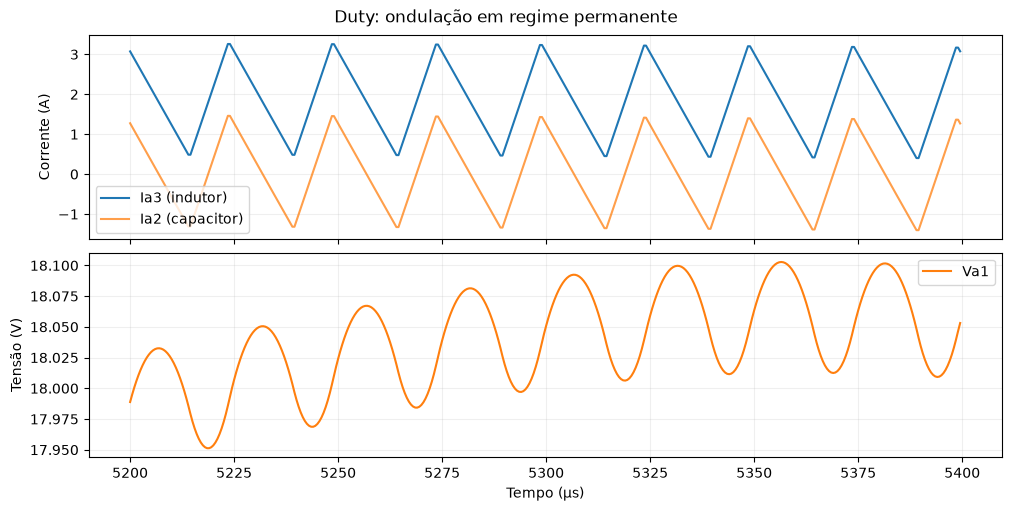

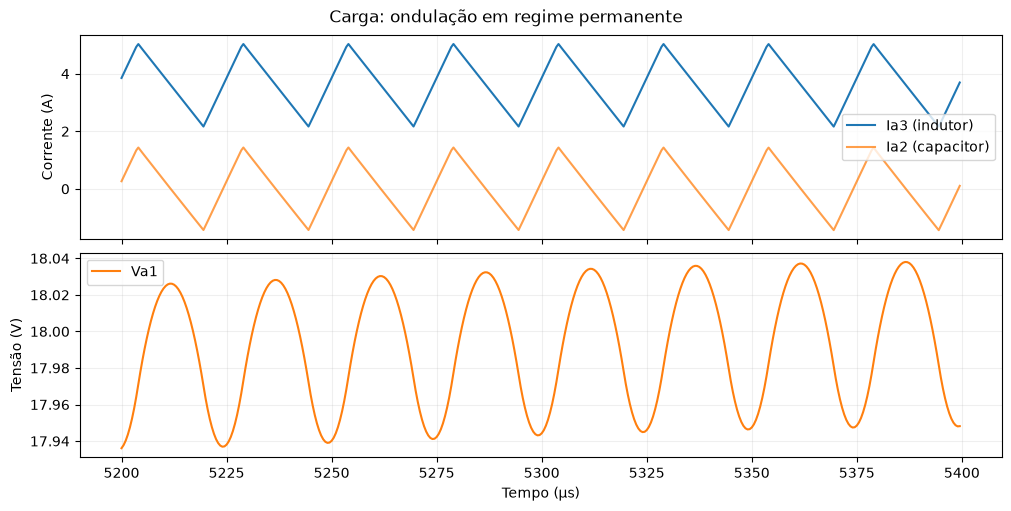

In [11]:
ripple_rows=[]
for kind,df in data.items():
    for stage,(a,b),d,r in [
        ('Antes',(-.0020,-.0020+5*TPWM),D0 if kind=='Duty' else D_LOAD,R0),
        ('Depois',(.0052,.0052+5*TPWM),D1 if kind=='Duty' else D_LOAD,R0 if kind=='Duty' else R1)]:
        s=win(df,a,b)
        expected=steady(d,r)
        dt=float(np.median(np.diff(s.Time)))
        ncycle=int(round(TPWM/dt))
        def got(col):
            vals=s[col].to_numpy()
            pps=[np.ptp(vals[i:i+ncycle]) for i in range(0,len(vals)-ncycle+1,ncycle)]
            return float(np.median(pps))
        ripple_rows.append({'Experimento':kind,'Estado':stage,'D':d,'R_ohm':r,
          'Ripple_Ia3_App':got('Ia3'),'Ripple_Ia3_teorico_App':expected['IL_ripple_App'],
          'Erro_ripple_Ia3_%':100*abs(got('Ia3')-expected['IL_ripple_App'])/expected['IL_ripple_App'],
          'Ripple_Ia2_App':got('Ia2'),'Ripple_Va1_mVpp':1000*got('Va1'),
          'Ripple_Va1_teorico_mVpp':1000*expected['Vout_ripple_Vpp']})
ripple=pd.DataFrame(ripple_rows);display(ripple.round(4))
ripple.to_csv(RESULTS/'ripple.csv',index=False)

for kind,df in data.items():
    s=win(df,.0052,.0052+8*TPWM)
    fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True,layout='constrained')
    axes[0].plot(s.Time*1e6,s.Ia3,label='Ia3 (indutor)')
    axes[0].plot(s.Time*1e6,s.Ia2,label='Ia2 (capacitor)',alpha=.75)
    axes[0].set_ylabel('Corrente (A)');axes[0].legend();axes[0].grid(alpha=.2)
    axes[1].plot(s.Time*1e6,s.Va1,label='Va1',color='tab:orange')
    axes[1].set_ylabel('Tensão (V)');axes[1].set_xlabel('Tempo (µs)')
    axes[1].legend();axes[1].grid(alpha=.2)
    fig.suptitle(f'{kind}: ondulação em regime permanente')
    fig.savefig(RESULTS/f'ripple_{kind.lower()}.png',dpi=160)
    plt.show()

## 8. Conclusões, verificações finais e limitações

### 8.1 O que foi validado

**Experimento 1 — Degrau de duty cycle (0,25 → 0,375, R = 10 Ω).** A tensão média passou de 11,997 V para 17,990 V, próxima das previsões de 12 V e 18 V. A resposta apresentou pico de 23,088 V, sobressinal de aproximadamente 85,08% da amplitude do degrau e tempo de acomodação estimado de 4,241 ms.

**Experimento 2 — Degrau de carga (10 Ω → 5 Ω, D = 0,375).** A corrente média na carga passou de 1,800 A para 3,598 A, próxima da previsão 1,8 → 3,6 A. A tensão caiu até 16,463 V e voltou a aproximadamente 17,989 V, com tempo de acomodação estimado de 1,452 ms.

**Regime permanente.** Em todas as linhas da tabela `comparacao_regime.csv`, o erro relativo da média simulada em relação ao valor teórico é inferior a 0,3%, portanto atende à tolerância de 5% estabelecida para a atividade. As relações de referência são:

$$
V_o \approx D V_{in}, \qquad I_{load} = \frac{V_o}{R}.
$$

**Lei de Kirchhoff.** O balanço `Ia3 = Ia1 + Ia2` foi verificado amostra por amostra, com erro máximo de 0,9 µA no ensaio de duty e 0,7 µA no ensaio de carga. Esses resíduos são compatíveis com arredondamento numérico dos arquivos CSV.

### 8.2 Interpretação física

- `Ia3` mede a corrente do indutor: ela não pode saltar instantaneamente, embora apresente ondulação de chaveamento e possa crescer rapidamente durante o transitório.
- `Ia1` mede a corrente na carga: ao conectar outra resistência em paralelo, ela pode sofrer um salto, pois a corrente resistiva depende instantaneamente de $V_{a1}/R_{eq}$.
- `Ia2` mede a corrente do capacitor, que fornece ou absorve a diferença entre a corrente do indutor e a corrente exigida pela carga.

### 8.3 Limitações da análise

1. O instante $t = 0$ dos CSVs corresponde ao trigger, não necessariamente ao comando que altera `In` ou `Load`. Os tempos transitórios apresentados foram calculados a partir de uma estimativa do instante do evento; devem ser interpretados com essa incerteza.
2. As métricas dependem da suavização usada para reduzir o ripple PWM e do critério de acomodação definido nas células anteriores. Não representam uma medição instrumental independente.
3. O modelo médio despreza os detalhes instantâneos do chaveamento; a comparação do ripple exige fórmulas próprias e os dados chaveados do Typhoon HIL.
4. Futuramente, exportar também `In` e `Load` ou programar os eventos para registrar com precisão a mudança de comando.